# The rock factor: where the one free number of the classical equation comes from

**Question:** How much does the rock factor vary inside a site and between sites?

**Level 2: The method in practice** · Needs: 02-classical-prediction/01-the-classical-equation-on-one-blast · Reading time: about 30 minutes

## Objectives

Both source papers say that the rock factor `A` "was estimated for each blast", and neither prints a value. Without it the classical equation cannot run. This notebook asks how much that one free number varies, inside a site and between sites, and tests the two ways the engine can obtain it: by inverting the equation on a published prediction, and from a published rating table.

By the end you will have:

- recovered a rock factor for every validation blast with a printed classical prediction, step by step through the engine, and grouped the results by site;
- measured the spread of the factor inside a site (which tests the geometry reconstruction) and between sites (which is the rock);
- shown that the engine's own derivation equals the table of factors it pins;
- compared the factors recovered from the two papers' columns, and run the three published rating schemes on the one site whose rock the corpus describes.

## Setup

Install the packages with the exact pins of `notebooks/requirements.txt`. The engine is `blastfrag`, published on PyPI; the other packages are its numerical base and the plotting library.

```bash
pip install blastfrag==0.4.0 numpy==2.5.4 matplotlib==3.11.2
```

The single setup cell below imports the packages, prints their installed versions so the output records which engine produced every number, sets the path to the committed artifacts and the plotting style, and defines `show_table`, a four-line helper that renders rows as a Markdown table because the notebook environment has no `pandas`.

In [1]:
# Imports, the pinned versions, the data path, the plotting style and one table helper
import itertools
import json
import re
from importlib.metadata import version
from pathlib import Path

import blastfrag as bf
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display

for name in ("blastfrag", "numpy", "matplotlib"):
    print(f"{name}=={version(name)}")

DERIVED = Path("../../../data/derived")
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})


def show_table(header, rows, left=1):
    # Render the rows as a Markdown table, the first `left` columns left-aligned and the others right-aligned
    lines = ["| " + " | ".join(header) + " |", "|" + ":---|" * left + "---:|" * (len(header) - left)]
    lines += ["| " + " | ".join(str(cell) for cell in row) + " |" for row in rows]
    text = "\n".join(lines)
    display({"text/markdown": text, "text/plain": text}, raw=True)

blastfrag==0.4.0
numpy==2.5.4
matplotlib==3.11.2


## Data

| Source | Owner and URL | Licence class | File the notebook reads |
|---|---|---|---|
| The validation blasts with the classical column each paper prints | Hudaverdi, Kulatilake and Kuzu 2010, https://doi.org/10.1002/nag.957; Kulatilake, Hudaverdi and Wu 2012, https://doi.org/10.1007/s10706-012-9496-3 | numeric facts reused with citation; the articles never ship | `bf.load_holdout()` inside the `blastfrag` wheel |
| The rock description of each site (strength, density, modulus) | the same articles, as carried in the committed benchmark | numeric facts reused with citation | `data/derived/benchmark.json`, field `site_meta` |
| The rating tables | Hudaverdi et al. 2010 Eqs. 2 and 3; Babaeian et al. 2019, https://doi.org/10.1016/j.jrmge.2018.11.006 (Tables 1 and 2) | the tables are reproduced with citation | `bf.rock_factor` and `bf.SCHEMES` in the engine |

## Method

**Route 1, a rating table.** Lilly's blastability index is the sum of five ratings (rock mass description, joint spacing, joint plane orientation, a density term and a strength term), and the rock factor is 0.06 times the index (Hudaverdi, Kulatilake and Kuzu 2010, https://doi.org/10.1002/nag.957, Eqs. 2 and 3). Babaeian et al. 2019 (https://doi.org/10.1016/j.jrmge.2018.11.006) print the same sum with a different strength term and different rating tables, and tabulate a third, five-band lookup by Hustrulid.

**Route 2, inversion.** The equation of the previous notebook is linear in `A`, so a published prediction `x50_pub` for a blast with known `V` and `Q` fixes it:

```
A = x50_pub / [ (V / Q)^0.8 * Q^(1/6) * (RWS / 115)^(-19/30) ]
```

The recovered value is only worth trusting if it is nearly the same for every blast of one site, because the rock does not change inside a campaign. That constancy is also a test of the geometry reconstruction: an error in burden or bench height would scatter the factor.

### Step 1: the published columns

The engine ships the two published validation sets as one union of 14 blasts and, for each blast, the predictions that each paper printed. The cell loads the union and lists, per site, how many validation blasts it has, how many of them have a known scale (inversion needs `V` and `Q`) and how many carry a printed 2012 classical size, the column the engine pins. The training corpus is loaded here too, since a later step needs it.

In [2]:
# The union of the two published validation sets: blasts per site and which carry a printed classical prediction
train = bf.load_training_corpus()
holdout = bf.load_holdout(protocol="union")
rows = []
for site in sorted({b.site for b in holdout}):
    members = [b for b in holdout if b.site == site]
    scaled = sum(bf.has_absolute_geometry(b) for b in members)
    printed = sum(b.meta["published"].get("kuzram_2012") is not None for b in members)
    rows.append((site, len(members), scaled, printed))
header = ["site", "validation blasts", "with a known scale",
          "with a printed 2012 classical size"]
show_table(header, rows)
print("printed columns of every blast:", sorted(holdout[0].meta["published"]))

| site | validation blasts | with a known scale | with a printed 2012 classical size |
|:---|---:|---:|---:|
| Akdaglar | 3 | 3 | 2 |
| Dongri-Buzurg | 1 | 1 | 1 |
| Enusa | 1 | 1 | 1 |
| Miami | 1 | 0 | 0 |
| Mrica | 1 | 1 | 1 |
| Murgul | 2 | 2 | 2 |
| Ozmert | 2 | 2 | 2 |
| Reocin | 1 | 1 | 1 |
| Reocin-UG | 1 | 1 | 1 |
| Soma | 1 | 1 | 1 |

printed columns of every blast: ['kuzram_2010', 'kuzram_2012', 'nn_mean_2012', 'regression_2010', 'regression_2012']


Twelve of the 14 validation blasts can be inverted: Miami's one blast has no scale, and one Akdaglar blast has no printed 2012 size. Six sites have a single usable blast, and three (Akdaglar, Murgul, Ozmert) have two, so the evidence on the spread inside a site will rest on three pairs. The five printed columns are two classical predictions (2010 and 2012), two regressions and one network; only the classical ones concern this notebook. The table counts blasts; it says nothing yet about the factor.

### Step 2: invert the equation on every blast

For each usable blast the cell reconstructs the pattern, takes its rock volume `V` and explosive mass `Q`, and calls `back_solve_rock_factor` with the 2012 printed size. The result is one rock factor per blast. The table lists each blast with the numbers that produced its factor, so every intermediate is visible.

In [3]:
# Invert the equation on each validation blast that has a scale and a printed 2012 classical size
per_blast = []
for blast in holdout:
    published = blast.meta["published"].get("kuzram_2012")
    if published is None or not bf.has_absolute_geometry(blast):
        continue
    pattern = bf.reconstruct_pattern(blast)
    volume, mass = pattern.rock_volume_m3, pattern.charge_mass_kg
    factor = bf.back_solve_rock_factor(published, rock_volume_m3=volume, charge_mass_kg=mass)
    per_blast.append((blast.blast_id, blast.site, published, volume, mass, factor))
rows = [(i, s, f"{x:.2f}", f"{v:.1f}", f"{q:.1f}", f"{a:.3f}") for i, s, x, v, q, a in per_blast]
header = ["blast", "site", "printed x50 (m)", "V (m3)", "Q (kg)", "recovered A"]
show_table(header, rows, left=2)

| blast | site | printed x50 (m) | V (m3) | Q (kg) | recovered A |
|:---|:---|---:|---:|---:|---:|
| En13 | Enusa | 0.44 | 150.2 | 72.1 | 10.973 |
| Ru7 | Reocin-UG | 0.65 | 263.5 | 81.7 | 11.191 |
| Mg8 | Murgul | 0.39 | 329.9 | 181.4 | 9.299 |
| Mg9 | Murgul | 0.30 | 243.2 | 182.4 | 9.160 |
| Rc1 | Reocin | 0.72 | 379.0 | 125.1 | 12.139 |
| Mr12 | Mrica | 0.24 | 108.0 | 51.8 | 6.324 |
| Db10 | Dongri-Buzurg | 0.08 | 40.0 | 35.6 | 3.677 |
| Sm8 | Soma | 0.35 | 674.9 | 283.5 | 6.244 |
| Oz8 | Ozmert | 0.20 | 45.0 | 23.9 | 6.493 |
| Oz9 | Ozmert | 0.23 | 72.8 | 34.2 | 6.387 |
| Ad23 | Akdaglar | 0.11 | 23.6 | 29.6 | 6.845 |
| Ad24 | Akdaglar | 0.13 | 22.2 | 19.7 | 6.594 |

The twelve factors run from 3.677 (Db10, Dongri-Buzurg, a 40 m3 blast with a printed 0.08 m) to 12.139 (Rc1, Reocin, a 379 m3 blast with a printed 0.72 m). The two Murgul blasts give 9.299 and 9.160, the two Ozmert blasts 6.493 and 6.387, the two Akdaglar blasts 6.845 and 6.594: close in pairs, far apart between sites. The table shows the factors blast by blast; whether the closeness within pairs is real or rounding is a question for the figure of the next step.

### Step 3: inside a site and between sites

The cell groups the factors by site and draws two panels. The left one places every blast's factor as a blue dot on a row per site, with the site mean as an orange tick. The right one compares the spread inside each site that has two blasts, measured as the maximum minus the minimum over the mean, with the same measure applied to the nine site means. If the factor is a property of the rock, the blue bars should be tiny and the orange one large.

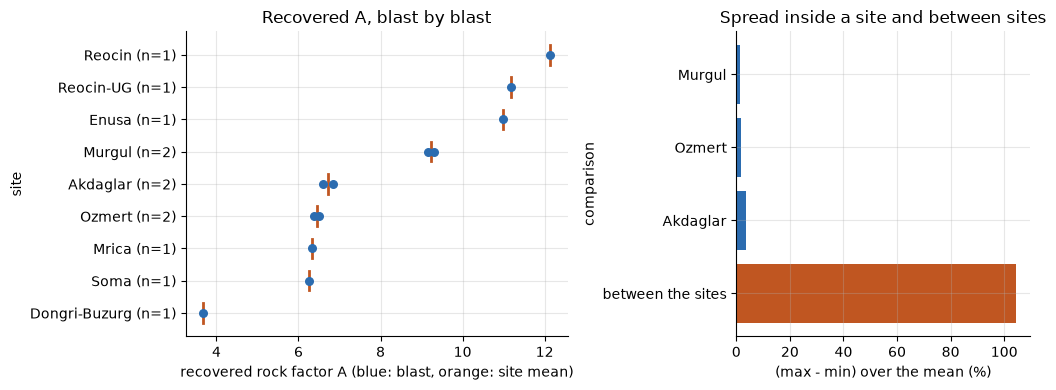

largest spread inside a site (%): 3.7
spread between the site means (%): 104
largest site mean over the smallest: 3.3


In [4]:
# Group the recovered factors by site: the mean, the spread inside the site and the range between sites
by_site = {}
for _, site, _, _, _, factor in per_blast:
    by_site.setdefault(site, []).append(factor)
means = {site: float(np.mean(values)) for site, values in by_site.items()}
spread = {site: (max(v) - min(v)) / np.mean(v) * 100 for site, v in by_site.items() if len(v) > 1}
between = (max(means.values()) - min(means.values())) / np.mean(list(means.values())) * 100
order = sorted(means, key=means.get)
fig, (left, right) = plt.subplots(1, 2, figsize=(10.5, 4), gridspec_kw={"width_ratios": [1.3, 1]})
for position, site in enumerate(order):
    left.scatter(by_site[site], [position] * len(by_site[site]), s=30, color="#2b6cb0", zorder=3)
    left.plot([means[site]] * 2, [position - 0.3, position + 0.3], color="#c05621", lw=2)
left.set_yticks(range(len(order)), [f"{site} (n={len(by_site[site])})" for site in order])
left.set_xlabel("recovered rock factor A (blue: blast, orange: site mean)")
left.set_ylabel("site")
left.set_title("Recovered A, blast by blast")
labels = [*spread, "between the sites"]
right.barh(range(len(labels)), [*spread.values(), between], color=["#2b6cb0"] * len(spread) + ["#c05621"])
right.set_yticks(range(len(labels)), labels)
right.invert_yaxis()
right.set_xlabel("(max - min) over the mean (%)")
right.set_ylabel("comparison")
right.set_title("Spread inside a site and between sites")
fig.tight_layout()
plt.show()
print("largest spread inside a site (%):", f"{max(spread.values()):.1f}")
print("spread between the site means (%):", f"{between:.0f}")
print("largest site mean over the smallest:", f"{max(means.values()) / min(means.values()):.1f}")

The two blasts of a site almost coincide, and the sites do not: the largest spread inside a site is 3.7 percent, at Akdaglar, while the spread between the nine site means is 104 percent of their mean, and the largest site mean is 3.3 times the smallest. A printed 0.11 m stands for anything from 0.105 to 0.115 m, a spread of 9 percent in itself, so a few percent of spread inside a site is what rounding the printed predictions to two decimals produces, and it is not a sign of a wrong geometry. The figure shows that the factor behaves as a constant of the site. It rests on only three pairs of blasts, so it supports the reconstruction without proving it.

### Step 4: the engine's derivation and the table it pins

The engine does the same grouping in one call, `derive_site_rock_factors`, and ships the result as the pinned table `SITE_ROCK_FACTOR`, the factors every classical predictor uses. The cell compares three things: the engine's derivation rounded to two decimals against the pinned table, and the means of the previous step against the engine's derivation. This is the notebook's only reproduction check, and it closes the loop: the factors used by the product are the ones derived here, step by step.

In [5]:
# The engine's own derivation, rounded to two decimals, against the table it pins and against the means above
derived = bf.derive_site_rock_factors("kuzram_2012")
same_table = all(round(mean, 2) == bf.SITE_ROCK_FACTOR[site] for site, (mean, _, _) in derived.items())
same_means = np.allclose([derived[s][0] for s in means], [means[s] for s in means], rtol=0, atol=1e-9)
print("derived factors equal the pinned table:", same_table, "| sites:", len(derived))
print("step-by-step means equal the engine's derivation:", same_means)

derived factors equal the pinned table: True | sites: 9
step-by-step means equal the engine's derivation: True


Both comparisons hold for all nine sites: the derived factors, rounded to two decimals, equal the pinned table, and the means computed step by step equal the engine's derivation to 1e-9. So the numbers of the previous steps are the numbers the product uses, with no hidden adjustment. The check says nothing about whether those numbers are right: they are derived from printed predictions, and the next steps look at the printed predictions themselves.

### Step 5: the two printed columns disagree

The 2010 paper printed larger classical sizes than the 2012 paper did for the same blasts. Inverting each column gives a different factor per site, because the factor is whatever makes the equation reproduce the column. `derive_site_rock_factors` takes the column as an argument; the cell derives both and tabulates the factors and their ratio. Mixing columns would be a defect, so the engine pins one.

In [6]:
# The factor recovered from each paper's printed column, site by site, and the ratio between the two
f2012 = bf.derive_site_rock_factors("kuzram_2012")
f2010 = bf.derive_site_rock_factors("kuzram_2010")
sites = sorted(f2010)
ratios = {site: f2010[site][0] / f2012[site][0] for site in sites}
rows = [(site, f"{f2012[site][0]:.2f}", f"{f2010[site][0]:.2f}", f"{ratios[site]:.3f}") for site in sites]
show_table(["site", "A (2012)", "A (2010)", "2010 / 2012"], rows)
values = list(ratios.values())
print(f"mean ratio: {np.mean(values):.3f} | range: {min(values):.3f} to {max(values):.3f}")

| site | A (2012) | A (2010) | 2010 / 2012 |
|:---|---:|---:|---:|
| Akdaglar | 6.72 | 7.03 | 1.045 |
| Dongri-Buzurg | 3.68 | 4.14 | 1.125 |
| Enusa | 10.97 | 11.97 | 1.091 |
| Mrica | 6.32 | 7.11 | 1.125 |
| Murgul | 9.23 | 10.05 | 1.088 |
| Ozmert | 6.44 | 7.04 | 1.094 |
| Reocin-UG | 11.19 | 12.22 | 1.092 |
| Soma | 6.24 | 6.78 | 1.086 |

mean ratio: 1.093 | range: 1.045 to 1.125


The 2010 column implies larger factors at every one of the eight sites it covers, by 1.045 to 1.125 times, 1.093 on average (Reocin has no 2010 printed size). The ratio is not constant, so the two papers did not differ by a single scaling: they printed different numbers for the same blasts. The factor is therefore a property of the pair (site, printed column) and not of the rock alone, which is why the engine pins the 2012 column, the one that also carries the other two published predictors, and never mixes the two.

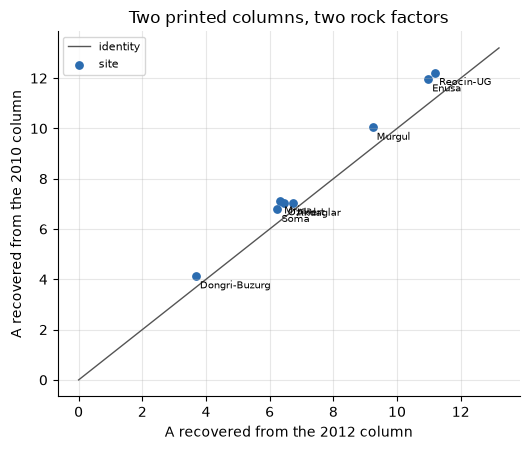

In [7]:
# Factor recovered from the 2010 column against the 2012 column, one point per site, with the identity line
x = np.array([f2012[s][0] for s in sites])
y = np.array([f2010[s][0] for s in sites])
fig, ax = plt.subplots(figsize=(5.4, 4.6))
limit = max(x.max(), y.max()) * 1.08
ax.plot([0, limit], [0, limit], color="#555", lw=1, label="identity")
ax.scatter(x, y, s=28, color="#2b6cb0", label="site")
for site, xi, yi in zip(sites, x, y):
    ax.annotate(site, (xi, yi), fontsize=7, xytext=(3, -9), textcoords="offset points")
ax.set_xlabel("A recovered from the 2012 column")
ax.set_ylabel("A recovered from the 2010 column")
ax.set_title("Two printed columns, two rock factors")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

Each point is one site: the factor recovered from the 2012 column on the horizontal axis and from the 2010 column on the vertical axis, with the identity line for reference. All eight points lie above the line, none far from it, and the order of the sites is almost the same in the two columns, so the two papers agree on which rock is hard and which is soft. The figure shows an offset between the columns, not a disagreement about the ranking; it does not say which column is the more accurate, and nothing in the corpus can.

### Step 6: what a rating table gives for the same rock

The rating schemes need a description of the rock. The corpus describes only Akdaglar's, in the committed benchmark (a sandstone, with its strength, density and modulus). The first cell parses that description into numbers and takes the mean in situ block of the site, which this notebook uses as the joint spacing, an assumption and not a datum. The second cell runs each scheme over every rock-mass category and joint-orientation category it recognises, since the corpus does not record those two, and keeps the lowest and highest factor each scheme can produce.

In [8]:
# Akdaglar's rock description from the benchmark, parsed into the numbers the rating tables need
benchmark = json.loads((DERIVED / "benchmark.json").read_text(encoding="utf-8"))
text = benchmark["site_meta"]["Akdaglar"]["rock"]
patterns = {"ucs": r"UCS ([\d.]+) MPa", "density": r"density ([\d.]+) g/cm3", "modulus": r"E ([\d.]+) GPa"}
found = {name: float(re.search(pattern, text)[1]) for name, pattern in patterns.items()}
ucs, density, modulus = found["ucs"], found["density"], found["modulus"]
block = float(np.mean([b.XB_m for b in train if b.site == "Akdaglar"]))
print("rock description:", text)
print(f"mean in situ block (m), used as the joint spacing: {block:.3f}")

rock description: sandstone, density 2.70 g/cm3, UCS 81 MPa, E 16.9 GPa
mean in situ block (m), used as the joint spacing: 1.185


Akdaglar is a sandstone of 2.70 g/cm3, with a strength of 81 MPa and a modulus of 16.9 GPa, and its mean in situ block is 1.185 m. The rating schemes also need a rock-mass description and a joint plane orientation that the corpus does not carry, so the next cell tries every category the tables recognise.

In [9]:
# Run every rating scheme over every rock-mass and joint category it recognises, and keep the extremes
masses = ("powdery", "blocky", "vertically_jointed", "massive")
orientations = ("horizontal", "dip_out_of_face", "strike_normal_to_face", "dip_into_face")
ranges = {}
for scheme in bf.SCHEMES:
    values = []
    for mass, orientation in itertools.product(masses, orientations):
        rock = bf.Rock(E_GPa=modulus, in_situ_block_m=block, ucs_mpa=ucs, density_t_m3=density,
                       rock_mass_description=mass, joint_spacing_m=block, joint_plane_orientation=orientation)
        try:
            values.append(bf.rock_factor(rock, scheme=scheme))
        except bf.rockfactor.RockFactorUnavailable:
            continue  # a category this scheme has no rating for
    ranges[scheme] = (min(values), max(values), len(values))
rows = [(scheme, f"{low:.2f}", f"{high:.2f}", f"{high / low:.2f}", n) for scheme, (low, high, n) in ranges.items()]
header = ["scheme", "lowest A", "highest A", "highest over lowest",
          "categories rated"]
show_table(header, rows)
print("recovered by inversion at Akdaglar:", bf.SITE_ROCK_FACTOR["Akdaglar"])

| scheme | lowest A | highest A | highest over lowest | categories rated |
|:---|---:|---:|---:|---:|
| lilly-hudaverdi | 2.75 | 4.85 | 1.76 | 12 |
| lilly-babaeian | 3.44 | 5.54 | 1.61 | 12 |
| hustrulid | 7.00 | 7.00 | 1.00 | 16 |

recovered by inversion at Akdaglar: 6.72


The Lilly scheme of Hudaverdi et al. spans 2.75 to 4.85 over its 12 categories, and the variant of Babaeian et al. spans 3.44 to 5.54 over 12; both bands lie below the 6.72 recovered by inversion. The Hustrulid lookup returns 7.00 for all 16 combinations, because it ignores the two categories, and is close to the recovered value. So the tables disagree with each other by as much as they disagree with the data, and the width of each Lilly band, a factor of about 1.8 and 1.6, is the price of two categories that nobody recorded.

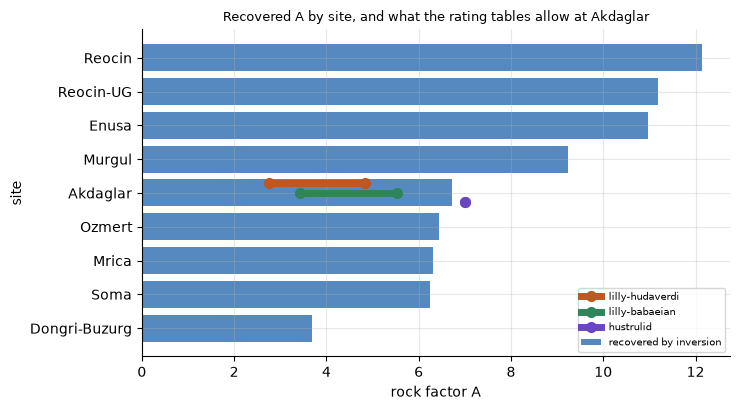

In [10]:
# The recovered factor of every site as bars, with the range each rating scheme allows drawn over Akdaglar
order = sorted(bf.SITE_ROCK_FACTOR, key=bf.SITE_ROCK_FACTOR.get)
fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.barh(order, [bf.SITE_ROCK_FACTOR[s] for s in order], color="#2b6cb0", alpha=0.8, label="recovered by inversion")
row = order.index("Akdaglar")
colors = {"lilly-hudaverdi": "#c05621", "lilly-babaeian": "#2f855a", "hustrulid": "#6b46c1"}
for offset, (scheme, (low, high, _)) in zip((0.28, 0.0, -0.28), ranges.items()):
    ax.plot([low, high], [row + offset] * 2, color=colors[scheme], lw=5, marker="o", ms=7, label=scheme)
ax.set_xlabel("rock factor A")
ax.set_ylabel("site")
ax.set_title("Recovered A by site, and what the rating tables allow at Akdaglar", fontsize=9)
ax.legend(fontsize=7, loc="lower right")
fig.tight_layout()
plt.show()

The blue bars are the factors recovered at each site, ordered; the three coloured segments over the Akdaglar bar are the ranges that the rating schemes can produce for its rock. The two Lilly segments end before the end of the bar, and the Hustrulid point sits slightly beyond it. The figure shows that no table pins the factor on this corpus: the two schemes that depend on categories give a wide band that misses the target, and the one that does not depend on them gives one number. It rests on a single site and on an assumed joint spacing, so it is a sample of the problem, not a verdict on the tables.

## Results

**Answer:** Inside a site the recovered rock factor varies by at most 3.7 percent, which is what the rounding of the printed predictions produces, while between the nine sites the factor varies by 104 percent of its mean and the largest site mean is 3.3 times the smallest. The factor behaves as a constant of the site, and the rock, not the arithmetic, carries the variation. The engine's derivation equals the table of factors it pins at all nine sites. The two printed columns give factors that differ by 1.045 to 1.125 times, and the rating tables do not pin the factor: at Akdaglar the two Lilly schemes span 2.75 to 4.85 and 3.44 to 5.54, against a recovered 6.72, while the Hustrulid lookup returns 7.00.

**What follows.** The classical predictor of the next notebooks uses these nine constants, and each is only as good as the printed column it was recovered from. A site with no printed prediction, or a new mine, has no factor at all unless something predicts it, which is the question of the last notebook of this topic.

**What this notebook does not show.** The recovered factors come from the published predictions of the very blasts the validation sets contain, so the classical predictor that uses them carries knowledge of the site it is scored on. The inside-site evidence rests on three pairs of blasts. The rating-table comparison uses one site and an assumed joint spacing. Neither route says which factor is physically correct.

## Summary

- The classical equation is linear in the rock factor, so a printed prediction fixes it, and `back_solve_rock_factor` recovers one factor per blast.
- Inside a site the factor varies by at most 3.7 percent and between the nine sites by 104 percent of the mean (largest over smallest, 3.3), so it behaves as a site constant.
- The engine's `derive_site_rock_factors` equals the table `SITE_ROCK_FACTOR` it pins at all nine sites.
- The 2010 and 2012 columns imply factors 1.045 to 1.125 times apart, and the engine pins the 2012 column.
- Rating tables cannot pin the factor on this corpus: at Akdaglar the Lilly schemes give 2.75 to 4.85 and 3.44 to 5.54 against 6.72 recovered.
- Next: notebook 03 scores the published predictors on their own validation tables (level 3).

## References

- Hudaverdi, Kulatilake and Kuzu 2010, https://doi.org/10.1002/nag.957 (Eqs. 1 to 3, the 2010 classical column)
- Kulatilake, Hudaverdi and Wu 2012, https://doi.org/10.1007/s10706-012-9496-3 (the 2012 validation set and its classical column)
- Babaeian et al. 2019, https://doi.org/10.1016/j.jrmge.2018.11.006 (Tables 1 and 2, the second rating table and the Hustrulid lookup)
- `blastfrag` 0.4.0, the engine, on PyPI: https://pypi.org/project/blastfrag/